<a href="https://colab.research.google.com/github/sheelathangarajan/dfu-prediction-dataset/blob/main/Project_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "gymnasium>=1.0,<2.0" stable-baselines3 matplotlib numpy pandas

In [ ]:
import gymnasium as gym
import stable_baselines3
import numpy as np
import matplotlib.pyplot as plt

print("Setup successful!")
print("Gymnasium:", gym.__version__)
print("Stable-Baselines3:", stable_baselines3.__version__)


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces

class RobotNavigationEnv(gym.Env):
    """2D robot navigation with fixed obstacles."""

    def __init__(self, render_mode=None):
        super().__init__()
        self.size = 10
        self.max_steps = 100
        self.start = np.array([0, 0])
        self.goal = np.array([9, 9])

        self.obstacles = {
            (2, 2), (2, 3), (2, 4),
            (4, 5), (5, 5), (6, 5),
            (7, 2), (7, 3), (7, 4)
        }

        # Actions: up, down, left, right
        self.action_space = spaces.Discrete(4)

        # Observation: robot x, y, goal x, y
        self.observation_space = spaces.Box(
            low=0, high=9, shape=(4,), dtype=np.float32
        )

        self.moves = {
            0: np.array([0, 1]),
            1: np.array([0, -1]),
            2: np.array([-1, 0]),
            3: np.array([1, 0])
        }

    def _get_obs(self):
        return np.array(
            [*self.position, *self.goal], dtype=np.float32
        )

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.position = self.start.copy()
        self.steps = 0
        return self._get_obs(), {}

    def step(self, action):
        self.steps += 1
        old_distance = np.linalg.norm(self.position - self.goal)

        new_position = self.position + self.moves[int(action)]
        reward = -1.0

        # Penalize obstacles and boundaries
        if (tuple(new_position) in self.obstacles or
            np.any(new_position < 0) or
            np.any(new_position >= self.size)):
            reward = -10.0
        else:
            self.position = new_position

        new_distance = np.linalg.norm(self.position - self.goal)
        reward += 0.5 * (old_distance - new_distance)

        reached_goal = np.array_equal(self.position, self.goal)
        terminated = bool(reached_goal)
        truncated = self.steps >= self.max_steps

        if reached_goal:
            reward += 100.0

        return self._get_obs(), reward, terminated, truncated, {}

env = RobotNavigationEnv()
obs, info = env.reset()

print("Robot navigation environment created successfully!")
print("Start position:", env.start)
print("Goal position:", env.goal)
print("Number of obstacles:", len(env.obstacles))
print("Initial observation:", obs)
print("Available actions:", env.action_space.n)


In [ ]:

def draw_environment(env, robot_position=None, title="Robot Navigation Environment"):
    if robot_position is None:
        robot_position = env.start

    fig, ax = plt.subplots(figsize=(7, 7))

    ax.set_xlim(-0.5, 9.5)
    ax.set_ylim(-0.5, 9.5)
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.grid(True, alpha=0.4)

    for x, y in env.obstacles:
        ax.add_patch(plt.Rectangle(
            (x - 0.45, y - 0.45), 0.9, 0.9,
            color="gray"
        ))

    ax.scatter(*env.goal, color="green", s=250,
               marker="*", label="Goal")
    ax.scatter(*robot_position, color="blue", s=150,
               marker="o", label="Robot")

    ax.set_xlabel("X position")
    ax.set_ylabel("Y position")
    ax.set_title(title)
    ax.legend()
    plt.show()

draw_environment(env)


In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.env_checker import check_env
import os

# Instantiate the environment locally to ensure it is defined
env = RobotNavigationEnv()

# Validate the custom environment
check_env(env, warn=True)
print("Environment validation successful!")

# Prepare the training environment
train_env = Monitor(RobotNavigationEnv())

# Create the PPO agent
model = PPO(
    "MlpPolicy",
    train_env,
    learning_rate=3e-4,
    n_steps=1024,
    batch_size=64,
    gamma=0.99,
    ent_coef=0.01,
    verbose=1,
    seed=42
)

# Train the robot
model.learn(total_timesteps=50000)

# Save locally
model.save("robot_navigation_ppo")
print("Saved locally: robot_navigation_ppo.zip")

# Automatically back up to Google Drive if mounted
backup_dir = "/content/drive/MyDrive/RL_Models/"
if os.path.exists("/content/drive"):
    os.makedirs(backup_dir, exist_ok=True)
    model.save(os.path.join(backup_dir, "robot_navigation_ppo"))
    print(f"Successfully backed up to Google Drive: {backup_dir}robot_navigation_ppo.zip")
else:
    print("Google Drive is not mounted yet. Model saved only to local storage.")

In [ ]:

test_env = RobotNavigationEnv()
obs, info = test_env.reset()

trajectory = [test_env.position.copy()]
total_reward = 0
terminated = False
truncated = False

while not (terminated or truncated):
    action, _ = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = test_env.step(action)

    trajectory.append(test_env.position.copy())
    total_reward += reward

trajectory = np.array(trajectory)
success = np.array_equal(test_env.position, test_env.goal)

print("Goal reached:", success)
print("Steps taken:", len(trajectory) - 1)
print("Total reward:", round(total_reward, 2))
print("Final robot position:", test_env.position)

# Plot the route
draw_environment(
    test_env,
    robot_position=test_env.position,
    title="Trained Robot - Final Position"
)

plt.figure(figsize=(7, 7))
plt.plot(trajectory[:, 0], trajectory[:, 1],
         "b-o", markersize=3, label="Robot path")
plt.scatter(*test_env.start, color="blue", s=120, label="Start")
plt.scatter(*test_env.goal, color="green", s=200, marker="*", label="Goal")

for x, y in test_env.obstacles:
    plt.scatter(x, y, color="gray", s=180, marker="s")

plt.xlim(-0.5, 9.5)
plt.ylim(-0.5, 9.5)
plt.xticks(range(10))
plt.yticks(range(10))
plt.grid(True)
plt.xlabel("X position")
plt.ylabel("Y position")
plt.title("PPO Robot Navigation Trajectory")
plt.legend()
plt.show()


NameError: name 'test_env' is not defined

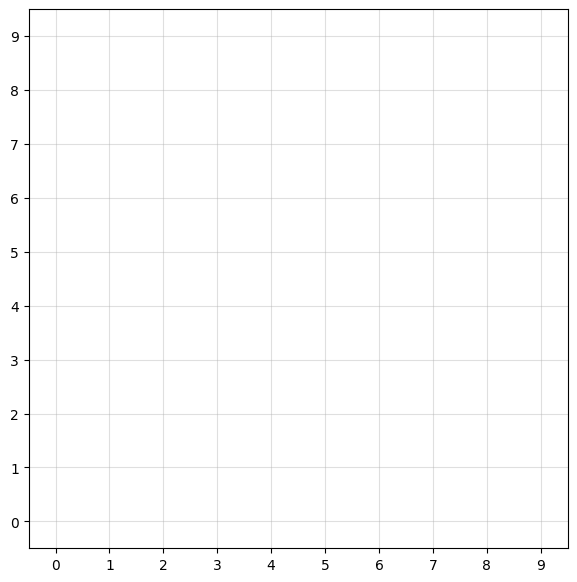

In [ ]:

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import matplotlib.pyplot as plt

# Use the trajectory recorded during Cell 6
fig, ax = plt.subplots(figsize=(7, 7))

ax.set_xlim(-0.5, 9.5)
ax.set_ylim(-0.5, 9.5)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_aspect("equal")
ax.grid(True, alpha=0.4)

# Draw obstacles
for x, y in test_env.obstacles:
    ax.add_patch(plt.Rectangle(
        (x - 0.4, y - 0.4), 0.8, 0.8,
        color="gray"
    ))

# Draw start and goal
ax.scatter(0, 0, color="blue", s=100, label="Start")
ax.scatter(9, 9, color="green", marker="*", s=250, label="Goal")

# Animated robot and its path
path_line, = ax.plot([], [], "b--", alpha=0.6)
robot, = ax.plot([], [], "ro", markersize=12)
status = ax.text(0.02, 1.02, "", transform=ax.transAxes)

ax.set_title("                                     PPO-Based Autonomous Robot Navigation")
ax.legend(loc="lower right")

def update(frame):
    path_line.set_data(
        trajectory[:frame + 1, 0],
        trajectory[:frame + 1, 1]
    )
    robot.set_data(
        [trajectory[frame, 0]],
        [trajectory[frame, 1]]
    )

    if frame == len(trajectory) - 1 and success:
        status.set_text("Goal reached successfully!")
    else:
        status.set_text(f"Navigation step: {frame}")

    return path_line, robot, status

animation = FuncAnimation(
    fig,
    update,
    frames=len(trajectory),
    interval=350,
    blit=True
)

plt.close(fig)
display(HTML(animation.to_jshtml()))


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Run evaluation to compute the missing metrics
num_episodes = 100
success_count = 0
steps_all = []
steps_success = []

eval_env = RobotNavigationEnv()

for _ in range(num_episodes):
    obs, info = eval_env.reset()
    terminated = False
    truncated = False
    steps = 0

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = eval_env.step(action)
        steps += 1

    steps_all.append(steps)
    reached_goal = np.array_equal(eval_env.position, eval_env.goal)
    if reached_goal:
        success_count += 1
        steps_success.append(steps)

success_rate = (success_count / num_episodes) * 100
average_steps_all = np.mean(steps_all) if steps_all else 0
average_steps_success = np.mean(steps_success) if steps_success else 0

# Now plot the results
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Success rate
axes[0].bar(
    ["PPO Agent"],
    [success_rate]
)
axes[0].set_ylim(0, 100)
axes[0].set_ylabel("Success rate (%)")
axes[0].set_title("Goal-Reaching Success Rate")

# Average steps
axes[1].bar(
    ["All episodes", "Successful episodes"],
    [average_steps_all, average_steps_success]
)
axes[1].set_ylabel("Average number of steps")
axes[1].set_title("Navigation Efficiency")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [ ]:

class RobotNavigationEvalEnv(RobotNavigationEnv):
    def reset(self, seed=None, options=None):
        obs, info = super().reset(seed=seed, options=options)
        self.collision_count = 0
        return obs, info

    def step(self, action):
        old_position = self.position.copy()

        obs, reward, terminated, truncated, info = super().step(action)

        # A collision occurs when the robot cannot move
        # because its proposed next position is blocked.
        if np.array_equal(old_position, self.position):
            proposed = old_position + self.moves[int(action)]

            if (tuple(proposed) in self.obstacles or
                np.any(proposed < 0) or
                np.any(proposed >= self.size)):
                self.collision_count += 1

        return obs, reward, terminated, truncated, info


def evaluate_agent(agent, num_episodes=100, random_agent=False):
    successes = 0
    total_collisions = 0
    total_steps = 0
    successful_steps = []

    for episode in range(num_episodes):
        eval_env = RobotNavigationEvalEnv()
        obs, info = eval_env.reset()
        terminated = False
        truncated = False
        steps = 0

        while not (terminated or truncated):
            if random_agent:
                action = eval_env.action_space.sample()
            else:
                action, _ = agent.predict(obs, deterministic=True)

            obs, reward, terminated, truncated, info = eval_env.step(action)
            steps += 1

        total_steps += steps
        total_collisions += eval_env.collision_count

        if terminated and np.array_equal(eval_env.position, eval_env.goal):
            successes += 1
            successful_steps.append(steps)

        eval_env.close()

    return {
        "Success rate (%)": 100 * successes / num_episodes,
        "Successful episodes": successes,
        "Total collisions": total_collisions,
        "Collisions per episode": total_collisions / num_episodes,
        "Average steps": total_steps / num_episodes,
        "Average steps on success": (
            np.mean(successful_steps) if successful_steps else np.nan
        )
    }


ppo_results = evaluate_agent(model, num_episodes=100)
print("PPO evaluation:")
for metric, value in ppo_results.items():
    print(f"{metric}: {value}")


In [ ]:

random_results = evaluate_agent(
    model,
    num_episodes=100,
    random_agent=True
)

print("RANDOM-ACTION BASELINE:")
for metric, value in random_results.items():
    print(f"{metric}: {value}")

print("\nPPO VS RANDOM BASELINE")
print("-" * 65)

for metric in [
    "Success rate (%)",
    "Collisions per episode",
    "Average steps"
]:
    print(
        f"{metric:25s} | "
        f"PPO: {ppo_results[metric]:8.2f} | "
        f"Random: {random_results[metric]:8.2f}"
    )


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "PPO": ppo_results,
    "Random": random_results
})

metrics = [
    ("Success rate (%)", "Goal-Reaching Success Rate"),
    ("Collisions per episode", "Average Collisions per Episode"),
    ("Average steps", "Average Steps per Episode")
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (metric, title) in zip(axes, metrics):
    comparison.loc[metric].plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

display(comparison.round(2))


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque

# Experiment settings
NUM_LAYOUTS = 20
NUM_OBSTACLES = 9
MAX_ATTEMPTS = 500

START = (0, 0)
GOAL = (9, 9)
SIZE = 10

# Check whether the goal is reachable in a proposed layout
def path_exists(obstacles):
    queue = deque([START])
    visited = {START}

    while queue:
        x, y = queue.popleft()

        if (x, y) == GOAL:
            return True

        for dx, dy in [(0, 1), (0, -1), (-1, 0), (1, 0)]:
            nxt = (x + dx, y + dy)

            if (0 <= nxt[0] < SIZE and
                0 <= nxt[1] < SIZE and
                nxt not in obstacles and
                nxt not in visited):
                visited.add(nxt)
                queue.append(nxt)

    return False


# Generate distinct, reachable obstacle layouts
rng = np.random.default_rng(2026)
layouts = []
layout_keys = set()

while len(layouts) < NUM_LAYOUTS:
    candidates = [
        (x, y)
        for x in range(SIZE)
        for y in range(SIZE)
        if (x, y) not in (START, GOAL)
    ]

    chosen = rng.choice(len(candidates),
                        size=NUM_OBSTACLES,
                        replace=False)

    obstacles = frozenset(candidates[i] for i in chosen)

    if obstacles in layout_keys:
        continue

    layout_keys.add(obstacles)

    if path_exists(obstacles):
        layouts.append(obstacles)

print(f"Generated {len(layouts)} new reachable layouts.")


# Evaluate the existing PPO model on every layout
results = []

for layout_id, obstacles in enumerate(layouts, start=1):
    eval_env = RobotNavigationEnv()
    eval_env.obstacles = set(obstacles)

    obs, info = eval_env.reset()
    terminated = False
    truncated = False
    steps = 0
    collisions = 0

    while not (terminated or truncated):
        action, _ = model.predict(obs, deterministic=True)

        old_position = eval_env.position.copy()
        proposed = old_position + eval_env.moves[int(action)]

        blocked = (
            tuple(proposed) in eval_env.obstacles or
            np.any(proposed < 0) or
            np.any(proposed >= SIZE)
        )

        obs, reward, terminated, truncated, info = eval_env.step(action)
        steps += 1

        if blocked:
            collisions += 1

    success = (
        terminated and
        np.array_equal(eval_env.position, eval_env.goal)
    )

    results.append({
        "Layout": layout_id,
        "Success": int(success),
        "Steps": steps,
        "Collision events": collisions,
        "Any collision": int(collisions > 0)
    })

    eval_env.close()


# Summarize the experiment
df_generalization = pd.DataFrame(results)

success_rate = 100 * df_generalization["Success"].mean()
collision_layout_rate = 100 * df_generalization["Any collision"].mean()
total_collisions = int(df_generalization["Collision events"].sum())
mean_collisions = df_generalization["Collision events"].mean()
average_steps = df_generalization["Steps"].mean()

print("\n===== PPO GENERALIZATION RESULTS =====")
print(f"Layouts tested: {NUM_LAYOUTS}")
print(f"Successful layouts: {df_generalization['Success'].sum()}")
print(f"Goal-reaching success rate: {success_rate:.1f}%")
print(f"Layouts with collisions: {df_generalization['Any collision'].sum()}")
print(f"Layouts with collisions (%): {collision_layout_rate:.1f}%")
print(f"Total collision events: {total_collisions}")
print(f"Average collision events per layout: {mean_collisions:.2f}")
print(f"Average steps per layout: {average_steps:.2f}")

display(df_generalization)


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Success/failure for each new layout
axes[0].bar(
    df_generalization["Layout"],
    df_generalization["Success"]
)
axes[0].set_title("PPO Success Across New Layouts")
axes[0].set_xlabel("Obstacle layout")
axes[0].set_ylabel("Success (1 = yes, 0 = no)")
axes[0].set_ylim(0, 1.2)
axes[0].set_xticks(range(1, NUM_LAYOUTS + 1, 2))

# Collision events for each layout
axes[1].bar(
    df_generalization["Layout"],
    df_generalization["Collision events"]
)
axes[1].set_title("Collision Events Across New Layouts")
axes[1].set_xlabel("Obstacle layout")
axes[1].set_ylabel("Collision events")
axes[1].set_xticks(range(1, NUM_LAYOUTS + 1, 2))

plt.tight_layout()
plt.show()

# Save experimental data for the QIP report
df_generalization.to_csv(
    "ppo_generalization_results.csv", index=False
)
print("Saved: ppo_generalization_results.csv")


In [ ]:
print("PPO Generalization Results")
print("--------------------------")
print(f"Layouts tested: {len(df_generalization)}")
print(f"Success rate: {df_generalization['Success'].mean() * 100:.1f}%")
print(f"Layouts with collisions: {df_generalization['Any collision'].mean() * 100:.1f}%")
print(f"Total collision events: {df_generalization['Collision events'].sum()}")
print(f"Average collisions per layout: {df_generalization['Collision events'].mean():.2f}")
print(f"Average steps per layout: {df_generalization['Steps'].mean():.2f}")

display(df_generalization)

In [ ]:
from google.colab import files
files.download("ppo_generalization_results.csv")

In [ ]:

import gymnasium as gym
from gymnasium import spaces
import numpy as np
from collections import deque

class RandomizedRobotNavigationEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.size = 10
        self.max_steps = 100
        self.start = np.array([0, 0])
        self.goal = np.array([9, 9])
        self.n_obstacles = 9

        self.moves = {
            0: np.array([0, 1]),   # Up
            1: np.array([0, -1]),  # Down
            2: np.array([-1, 0]),  # Left
            3: np.array([1, 0])    # Right
        }
        self.action_space = spaces.Discrete(4)

        # Observation: robot position (2) + goal (2) + obstacle map (100)
        low = np.zeros(104, dtype=np.float32)
        high = np.array([9, 9, 9, 9] + [1] * 100,
                        dtype=np.float32)
        self.observation_space = spaces.Box(
            low=low, high=high, dtype=np.float32
        )

        self.obstacles = set()
        self.position = self.start.copy()
        self.steps = 0
        self.collision_count = 0

    def path_exists(self, obstacles):
        start = tuple(self.start)
        goal = tuple(self.goal)
        queue = deque([start])
        visited = {start}

        while queue:
            x, y = queue.popleft()
            if (x, y) == goal:
                return True

            for move in self.moves.values():
                nxt = (x + int(move[0]), y + int(move[1]))
                if (0 <= nxt[0] < self.size and
                    0 <= nxt[1] < self.size and
                    nxt not in obstacles and nxt not in visited):
                    visited.add(nxt)
                    queue.append(nxt)
        return False

    def generate_layout(self):
        cells = [
            (x, y)
            for x in range(self.size)
            for y in range(self.size)
            if (x, y) not in {(0, 0), (9, 9)}
        ]

        while True:
            indices = self.np_random.choice(
                len(cells), size=self.n_obstacles, replace=False
            )
            obstacles = {cells[int(i)] for i in indices}
            if self.path_exists(obstacles):
                return obstacles

    def get_obs(self):
        obstacle_map = np.zeros(100, dtype=np.float32)

        # Encode each obstacle in a 10 x 10 grid
        for x, y in self.obstacles:
            obstacle_map[x * 10 + y] = 1.0

        return np.concatenate([
            self.position.astype(np.float32),
            self.goal.astype(np.float32),
            obstacle_map
        ])

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        if options is not None and "obstacles" in options:
            self.obstacles = {
                tuple(map(int, cell))
                for cell in options["obstacles"]
            }
        else:
            self.obstacles = self.generate_layout()

        self.position = self.start.copy()
        self.steps = 0
        self.collision_count = 0

        return self.get_obs(), {}

    def step(self, action):
        self.steps += 1
        old_distance = np.linalg.norm(self.position - self.goal)
        proposed = self.position + self.moves[int(action)]

        collision = (
            tuple(proposed) in self.obstacles
            or np.any(proposed < 0)
            or np.any(proposed >= self.size)
        )

        reward = -1.0

        if collision:
            reward -= 10.0
            self.collision_count += 1
        else:
            self.position = proposed

        new_distance = np.linalg.norm(self.position - self.goal)
        reward += 0.5 * (old_distance - new_distance)

        reached_goal = np.array_equal(self.position, self.goal)
        terminated = bool(reached_goal)
        truncated = self.steps >= self.max_steps

        if reached_goal:
            reward += 100.0

        return self.get_obs(), reward, terminated, truncated, {}


In [ ]:

from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.env_checker import check_env

# Create and verify the new environment
random_env = RandomizedRobotNavigationEnv()
check_env(random_env, warn=True)

# Train PPO on randomized obstacle layouts
train_env2 = Monitor(RandomizedRobotNavigationEnv())

model2 = PPO(
    "MlpPolicy",
    train_env2,
    learning_rate=3e-4,
    n_steps=1024,
    batch_size=64,
    gamma=0.99,
    ent_coef=0.01,
    verbose=1,
    seed=123
)

model2.learn(total_timesteps=100000)
model2.save("robot_navigation_ppo_obstacle_aware")

print("Second PPO agent training completed!")


In [ ]:

import pandas as pd
import numpy as np

# Confirm the previous experiment's 20 layouts are available
print("Number of test layouts:", len(layouts))

def test_original_agent(layout):
    env = RobotNavigationEnv()
    env.obstacles = set(layout)

    obs, _ = env.reset()
    collisions = 0

    for step in range(1, env.max_steps + 1):
        action, _ = model.predict(obs, deterministic=True)

        old_position = env.position.copy()
        proposed = old_position + env.moves[int(action)]

        blocked = (
            tuple(proposed) in env.obstacles
            or np.any(proposed < 0)
            or np.any(proposed >= env.size)
        )

        obs, reward, terminated, truncated, info = env.step(action)

        if blocked:
            collisions += 1

        if terminated or truncated:
            break

    success = np.array_equal(env.position, env.goal)
    return success, step, collisions


def test_obstacle_aware_agent(layout):
    env = RandomizedRobotNavigationEnv()

    obs, _ = env.reset(options={"obstacles": layout})

    for step in range(1, env.max_steps + 1):
        action, _ = model2.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)

        if terminated or truncated:
            break

    success = np.array_equal(env.position, env.goal)
    return success, step, env.collision_count


results = []

for i, layout in enumerate(layouts, start=1):
    old_success, old_steps, old_collisions = test_original_agent(layout)
    new_success, new_steps, new_collisions = test_obstacle_aware_agent(layout)

    results.append({
        "Layout": i,
        "Original PPO Success": old_success,
        "Original PPO Steps": old_steps,
        "Original PPO Collisions": old_collisions,
        "Obstacle-Aware PPO Success": new_success,
        "Obstacle-Aware PPO Steps": new_steps,
        "Obstacle-Aware PPO Collisions": new_collisions
    })

results_df = pd.DataFrame(results)
display(results_df)

# Calculate overall metrics
summary = pd.DataFrame({
    "Metric": [
        "Success rate (%)",
        "Successful layouts",
        "Total collisions",
        "Average collisions per layout",
        "Average steps per layout",
        "Average steps on successful layouts"
    ],
    "Original PPO": [
        100 * results_df["Original PPO Success"].mean(),
        results_df["Original PPO Success"].sum(),
        results_df["Original PPO Collisions"].sum(),
        results_df["Original PPO Collisions"].mean(),
        results_df["Original PPO Steps"].mean(),
        results_df.loc[
            results_df["Original PPO Success"], "Original PPO Steps"
        ].mean()
    ],
    "Obstacle-Aware PPO": [
        100 * results_df["Obstacle-Aware PPO Success"].mean(),
        results_df["Obstacle-Aware PPO Success"].sum(),
        results_df["Obstacle-Aware PPO Collisions"].sum(),
        results_df["Obstacle-Aware PPO Collisions"].mean(),
        results_df["Obstacle-Aware PPO Steps"].mean(),
        results_df.loc[
            results_df["Obstacle-Aware PPO Success"],
            "Obstacle-Aware PPO Steps"
        ].mean()
    ]
})

display(summary.round(2))

results_df.to_csv("ppo_same_layout_comparison.csv", index=False)
summary.to_csv("ppo_comparison_summary.csv", index=False)

print("Saved: ppo_same_layout_comparison.csv")
print("Saved: ppo_comparison_summary.csv")


In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.monitor import Monitor
import os

# Re-create or load model2 if it was cleared during runtime reset
try:
    # Try to load model2 from active memory
    _ = model2
except NameError:
    print("model2 was not found in memory. Attempting to load from fallback file...")
    try:
        model2 = PPO.load("robot_navigation_ppo_obstacle_aware")
        print("Successfully loaded 100k fallback model.")
    except Exception as e:
        print(f"Could not load fallback model: {e}. Re-instantiating a fresh model2 agent...")
        train_env2 = Monitor(RandomizedRobotNavigationEnv())
        model2 = PPO(
            "MlpPolicy",
            train_env2,
            learning_rate=3e-4,
            n_steps=1024,
            batch_size=64,
            gamma=0.99,
            ent_coef=0.01,
            verbose=1,
            seed=123
        )

# Continue training the existing obstacle-aware PPO agent
model2.learn(
    total_timesteps=400000,
    reset_num_timesteps=False
)

# Save locally
model2.save("robot_navigation_ppo_obstacle_aware_500k")
print("Saved locally: robot_navigation_ppo_obstacle_aware_500k.zip")

# Automatically back up to Google Drive if mounted
backup_dir = "/content/drive/MyDrive/RL_Models/"
if os.path.exists("/content/drive"):
    os.makedirs(backup_dir, exist_ok=True)
    model2.save(os.path.join(backup_dir, "robot_navigation_ppo_obstacle_aware_500k"))
    print(f"Successfully backed up to Google Drive: {backup_dir}robot_navigation_ppo_obstacle_aware_500k.zip")
else:
    print("Google Drive is not mounted yet. Model saved only to local storage.")

print("Training completed: approximately 500,000 total timesteps.")

Streaming output truncated to the last 5000 lines.
| rollout/                |             |
|    ep_len_mean          | 30.2        |
|    ep_rew_mean          | -0.752      |
| time/                   |             |
|    fps                  | 660         |
|    iterations           | 154         |
|    time_elapsed         | 238         |
|    total_timesteps      | 157696      |
| train/                  |             |
|    approx_kl            | 0.008379513 |
|    clip_fraction        | 0.0247      |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.912      |
|    explained_variance   | 0.239       |
|    learning_rate        | 0.0003      |
|    loss                 | 225         |
|    n_updates            | 1530        |
|    policy_gradient_loss | -0.00227    |
|    value_loss           | 1.66e+03    |
-----------------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean         

In [ ]:
# @title
import sys
import os

# 1. Automatically reinstall packages if the Colab session was reset
try:
    import stable_baselines3
    import gymnasium as gym
except ImportError:
    print("Session reset detected. Re-installing required packages...")
    !pip install -q "gymnasium>=1.0,<2.0" stable-baselines3 pandas numpy matplotlib
    import gymnasium as gym
    import stable_baselines3

import pandas as pd
import numpy as np
from collections import deque
from gymnasium import spaces
from stable_baselines3 import PPO

# 2. Re-declare the environments so that PPO.load can correctly instantiate the model's environments
class RobotNavigationEnv(gym.Env):
    def __init__(self, render_mode=None):
        super().__init__()
        self.size = 10
        self.max_steps = 100
        self.start = np.array([0, 0])
        self.goal = np.array([9, 9])
        self.obstacles = {(2, 2), (2, 3), (2, 4), (4, 5), (5, 5), (6, 5), (7, 2), (7, 3), (7, 4)}
        self.action_space = spaces.Discrete(4)
        self.observation_space = spaces.Box(low=0, high=9, shape=(4,), dtype=np.float32)
        self.moves = {0: np.array([0, 1]), 1: np.array([0, -1]), 2: np.array([-1, 0]), 3: np.array([1, 0])}

    def _get_obs(self):
        return np.array([*self.position, *self.goal], dtype=np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.position = self.start.copy()
        self.steps = 0
        return self._get_obs(), {}

    def step(self, action):
        self.steps += 1
        old_distance = np.linalg.norm(self.position - self.goal)
        new_position = self.position + self.moves[int(action)]
        reward = -1.0
        if (tuple(new_position) in self.obstacles or np.any(new_position < 0) or np.any(new_position >= self.size)):
            reward = -10.0
        else:
            self.position = new_position
        new_distance = np.linalg.norm(self.position - self.goal)
        reward += 0.5 * (old_distance - new_distance)
        reached_goal = np.array_equal(self.position, self.goal)
        terminated = bool(reached_goal)
        truncated = self.steps >= self.max_steps
        if reached_goal:
            reward += 100.0
        return self._get_obs(), reward, terminated, truncated, {}

class RandomizedRobotNavigationEnv(gym.Env):
    def __init__(self):
        super().__init__()
        self.size = 10
        self.max_steps = 100
        self.start = np.array([0, 0])
        self.goal = np.array([9, 9])
        self.n_obstacles = 9
        self.moves = {0: np.array([0, 1]), 1: np.array([0, -1]), 2: np.array([-1, 0]), 3: np.array([1, 0])}
        self.action_space = spaces.Discrete(4)
        low = np.zeros(104, dtype=np.float32)
        high = np.array([9, 9, 9, 9] + [1] * 100, dtype=np.float32)
        self.observation_space = spaces.Box(low=low, high=high, dtype=np.float32)
        self.obstacles = set()
        self.position = self.start.copy()
        self.steps = 0
        self.collision_count = 0

    def path_exists(self, obstacles):
        start = tuple(self.start)
        goal = tuple(self.goal)
        queue = deque([start])
        visited = {start}
        while queue:
            x, y = queue.popleft()
            if (x, y) == goal:
                return True
            for move in self.moves.values():
                nxt = (x + int(move[0]), y + int(move[1]))
                if (0 <= nxt[0] < self.size and 0 <= nxt[1] < self.size and nxt not in obstacles and nxt not in visited):
                    visited.add(nxt)
                    queue.append(nxt)
        return False

    def generate_layout(self):
        cells = [(x, y) for x in range(self.size) for y in range(self.size) if (x, y) not in {(0, 0), (9, 9)}]
        while True:
            indices = self.np_random.choice(len(cells), size=self.n_obstacles, replace=False)
            obstacles = {cells[int(i)] for i in indices}
            if self.path_exists(obstacles):
                return obstacles

    def get_obs(self):
        obstacle_map = np.zeros(100, dtype=np.float32)
        for x, y in self.obstacles:
            obstacle_map[x * 10 + y] = 1.0
        return np.concatenate([self.position.astype(np.float32), self.goal.astype(np.float32), obstacle_map])

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        if options is not None and "obstacles" in options:
            self.obstacles = {tuple(map(int, cell)) for cell in options["obstacles"]}
        else:
            self.obstacles = self.generate_layout()
        self.position = self.start.copy()
        self.steps = 0
        self.collision_count = 0
        return self.get_obs(), {}

    def step(self, action):
        self.steps += 1
        old_distance = np.linalg.norm(self.position - self.goal)
        proposed = self.position + self.moves[int(action)]
        collision = (tuple(proposed) in self.obstacles or np.any(proposed < 0) or np.any(proposed >= self.size))
        reward = -1.0
        if collision:
            reward -= 10.0
            self.collision_count += 1
        else:
            self.position = proposed
        new_distance = np.linalg.norm(self.position - self.goal)
        reward += 0.5 * (old_distance - new_distance)
        reached_goal = np.array_equal(self.position, self.goal)
        terminated = bool(reached_goal)
        truncated = self.steps >= self.max_steps
        if reached_goal:
            reward += 100.0
        return self.get_obs(), reward, terminated, truncated, {}

# Register the custom envs in SB3 so model loading works flawlessly
from stable_baselines3.common.envs import SimpleMultiObsEnv

# 3. Re-create the 20 reachable layouts with the same seed 2026
NUM_LAYOUTS = 20
NUM_OBSTACLES = 9
START = (0, 0)
GOAL = (9, 9)
SIZE = 10

def path_exists_layout(obstacles):
    queue = deque([START])
    visited = {START}
    while queue:
        x, y = queue.popleft()
        if (x, y) == GOAL:
            return True
        for dx, dy in [(0, 1), (0, -1), (-1, 0), (1, 0)]:
            nxt = (x + dx, y + dy)
            if (0 <= nxt[0] < SIZE and 0 <= nxt[1] < SIZE and nxt not in obstacles and nxt not in visited):
                visited.add(nxt)
                queue.append(nxt)
    return False

rng = np.random.default_rng(2026)
layouts = []
layout_keys = set()

while len(layouts) < NUM_LAYOUTS:
    candidates = [(x, y) for x in range(SIZE) for y in range(SIZE) if (x, y) not in (START, GOAL)]
    chosen = rng.choice(len(candidates), size=NUM_OBSTACLES, replace=False)
    obstacles = frozenset(candidates[i] for i in chosen)
    if obstacles in layout_keys:
        continue
    layout_keys.add(obstacles)
    if path_exists_layout(obstacles):
        layouts.append(obstacles)

# 4. Load the saved model from disk
try:
    model2 = PPO.load("robot_navigation_ppo_obstacle_aware_500k")
    print("Successfully loaded the 500k model from disk!")
except Exception as e:
    print(f"Could not load 500k model: {e}. Trying to load 100k fallback...")
    model2 = PPO.load("robot_navigation_ppo_obstacle_aware")

def evaluate_agent(model_to_test, layout, obstacle_aware=False):
    if obstacle_aware:
        env = RandomizedRobotNavigationEnv()
    else:
        env = RobotNavigationEnv()

    obs, _ = env.reset(options={"obstacles": layout}) if obstacle_aware else env.reset()
    if not obstacle_aware:
        env.obstacles = set(layout)
        obs, _ = env.reset()
        env.obstacles = set(layout)

    collisions = 0
    for step in range(1, env.max_steps + 1):
        action, _ = model_to_test.predict(obs, deterministic=True)
        old_position = env.position.copy()
        proposed = old_position + env.moves[int(action)]
        blocked = (tuple(proposed) in env.obstacles or np.any(proposed < 0) or np.any(proposed >= env.size))
        obs, reward, terminated, truncated, info = env.step(action)
        if blocked:
            collisions += 1
        if terminated or truncated:
            break

    success = np.array_equal(env.position, env.goal)
    return success, step, collisions

results_500k = []
for i, layout in enumerate(layouts, start=1):
    success, steps, collisions = evaluate_agent(model2, layout, obstacle_aware=True)
    results_500k.append({
        "Layout": i,
        "Success": success,
        "Steps": steps,
        "Collisions": collisions
    })

df_500k = pd.DataFrame(results_500k)
display(df_500k)

summary_500k = pd.DataFrame({
    "Metric": [
        "Success rate (%)",
        "Successful layouts",
        "Total collisions",
        "Average collisions per layout",
        "Average steps per layout"
    ],
    "Obstacle-Aware PPO (100K)": [10, 2, 1675, 83.75, 91.80],
    "Obstacle-Aware PPO (500K)": [
        df_500k["Success"].mean() * 100,
        df_500k["Success"].sum(),
        df_500k["Collisions"].sum(),
        df_500k["Collisions"].mean(),
        df_500k["Steps"].mean()
    ]
})

display(summary_500k.round(2))

df_500k.to_csv("ppo_obstacle_aware_500k_results.csv", index=False)
summary_500k.to_csv("ppo_obstacle_aware_training_comparison.csv", index=False)
print("500K evaluation completed.")

### Saving Models to Google Drive
To prevent losing your trained reinforcement learning agents when the ephemeral Colab session resets or times out, you can mount your personal Google Drive and save the weights directly there.

In [ ]:
from google.colab import drive
import os

# 1. Mount your Google Drive
drive.mount('/content/drive')

# 2. Define a folder in your Drive to save RL models
backup_dir = "/content/drive/MyDrive/RL_Models/"
os.makedirs(backup_dir, exist_ok=True)

print(f"Google Drive successfully mounted. Models will be saved to: {backup_dir}")

# 3. Save your trained models to your Google Drive folder
# (Make sure model and model2 are trained and defined before running this)
try:
    model.save(os.path.join(backup_dir, "robot_navigation_ppo"))
    print("Saved model (100k fixed) to Google Drive!")
except NameError:
    print("model is not defined in memory yet. Train it before saving.")

try:
    model2.save(os.path.join(backup_dir, "robot_navigation_ppo_obstacle_aware_500k"))
    print("Saved model2 (500k obstacle-aware) to Google Drive!")
except NameError:
    print("model2 is not defined in memory yet. Train it before saving.")